In [96]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dropout
from tensorflow.keras.models import Model

## My second analysis in applying CNN

In this analysis I would like to apply edges around the images and change the background colour in order to find out if I can fight my overfitting problem as shown in the first analysis, which included the resizing of images to see if that made any difference. 

Most of the methods will be the same as in the previous analysis because I want to make some changes in the preprocess_image_for_cnn method to show my progress in how I'm trying to fight the overfitting problem.

In [3]:
# Define the path to the training folder
training_dir = 'ASL_Dataset/Train'

# Function to preprocess an image
def preprocess_image_for_cnn(file_path, img_size=(64, 64)):
    # Read the image in grayscale
    img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
    
    # Apply Gaussian blur to reduce noise
    img = cv2.GaussianBlur(img, (5, 5), 0)
    
    # # Apply Canny Edge Detection to get the outline
    edges = cv2.Canny(img, threshold1=50, threshold2=150)
    
    # Resize to the desired input size
    edges = cv2.resize(edges, img_size)
    
    # Normalize pixel values
    edges = edges / 255.0
    
    return img

The only difference with the processing of my images prior to the previous analysis I did is that this time the images are getting processed with edges around them. So there is a minor difference compared to the previous analysis.

Displaying preprocessed images from folder: A


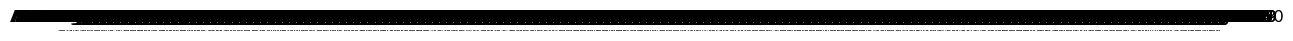

Displaying preprocessed images from folder: B


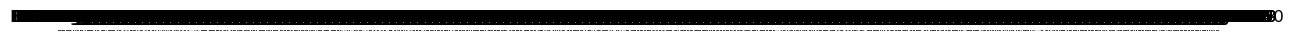

Displaying preprocessed images from folder: C


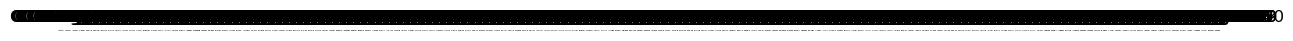

Displaying preprocessed images from folder: D


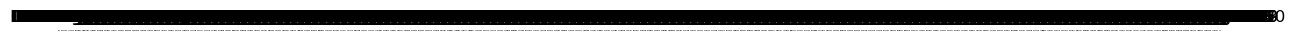

Displaying preprocessed images from folder: E


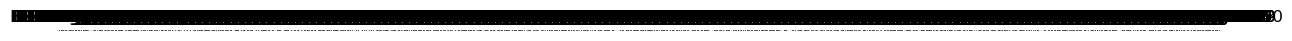

Displaying preprocessed images from folder: F


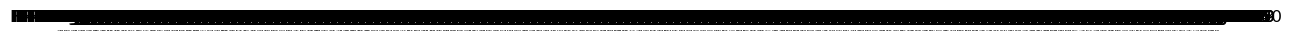

Displaying preprocessed images from folder: G


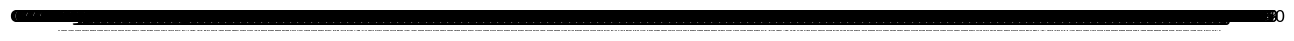

Displaying preprocessed images from folder: H


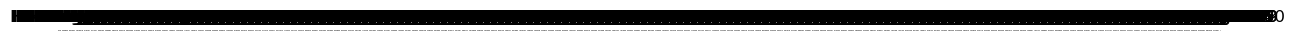

Displaying preprocessed images from folder: I


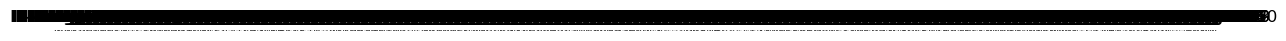

Displaying preprocessed images from folder: K


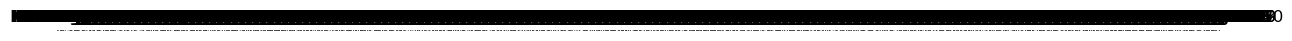

Displaying preprocessed images from folder: L


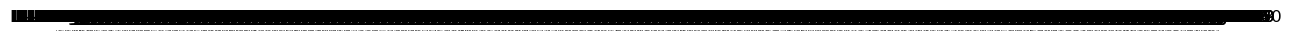

Displaying preprocessed images from folder: M


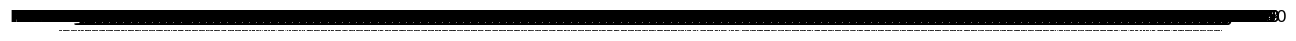

Displaying preprocessed images from folder: N


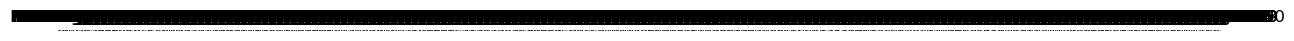

Displaying preprocessed images from folder: O


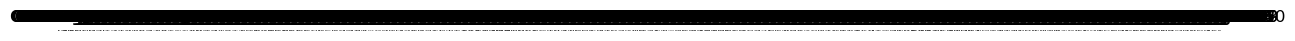

Displaying preprocessed images from folder: P


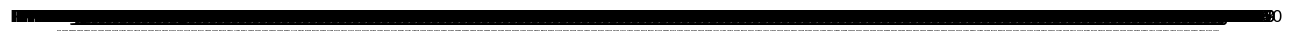

Displaying preprocessed images from folder: Q


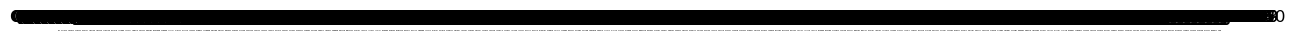

Displaying preprocessed images from folder: R


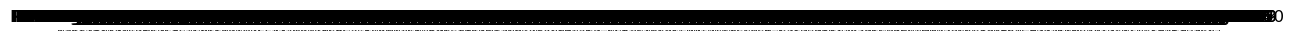

Displaying preprocessed images from folder: S


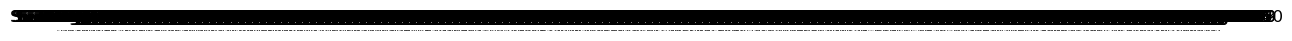

Displaying preprocessed images from folder: T


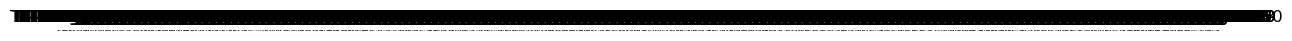

Displaying preprocessed images from folder: U


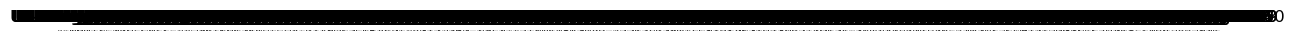

Displaying preprocessed images from folder: V


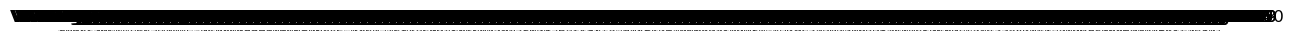

Displaying preprocessed images from folder: W


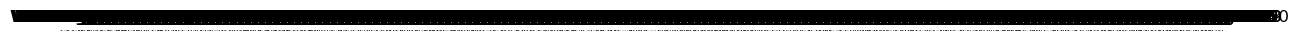

Displaying preprocessed images from folder: X


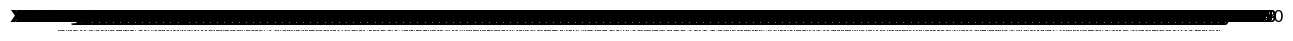

Displaying preprocessed images from folder: Y


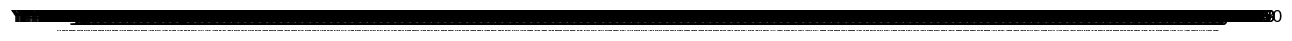

In [15]:
# Function to display images from each subfolder with preprocessing
def display_dataset_with_preprocessing(folder_path, num_images):
    
    # Folders I would like to exclude form the image processing
    exclude_folders = ["Space", "Nothing", "J", "Z"]
    
    # Iterate through each subfolder (a-z) in the training directory
    for subfolder in sorted(os.listdir(folder_path)):
        subfolder_path = os.path.join(folder_path, subfolder)
        
        # Check if the subfolder is a directory
        if os.path.isdir(subfolder_path) and subfolder.strip() not in exclude_folders:
            # Get all file names within the subfolder
            files = os.listdir(subfolder_path)
            
            # Limit to the first few files
            files = files[:num_images]

            # Display a few images from this subfolder
            print(f"Displaying preprocessed images from folder: {subfolder}")
            
            # Create a plot with num_images columns
            plt.figure(figsize=(15, 5))
            
            for i, file in enumerate(files):
                file_path = os.path.join(subfolder_path, file)
                
                # Preprocess image
                preprocessed_img = preprocess_image_for_cnn(file_path)
                
                # Display image in a subplot
                plt.subplot(1, num_images, i + 1)
                plt.imshow(preprocessed_img, cmap='gray')  
                plt.title(f'{subfolder} - Image {i + 1}')
                plt.axis('off')
        
        # Show all plots for this subfolder
        plt.show()

# Call the function to display preprocessed images
display_dataset_with_preprocessing(training_dir, num_images=1000)

I have modified this method multiple times because of errors I encountered during my testing phase. I also wanted to create a method that was more dynamic in a sense of adding my own values as an easy way to reuse this method for adding different values, like argumentation, playing with the size of the image, filtering out values that are currently not being used, and the amount of image I would like to use for my test and training data. Beneath is a small explanation of the method itself.

In the create data set I used the X and Y values for storing their corresponding labels. The name labels are derived from the subdirectory names in the dataset path. In the label_map I Map each class name to a unique integer index for training. The reason why is because of assigning numeric labels ensures compatibility with machine learning models that require numerical inputs.

In the next step, I'm looping through my labels to ensure that the structure is traversed correctly and non-directory files (if any) in the root folder are ignored. After that I'm looping again through the amount of images I want to preprocess for my training and putting them afterward directly into my preprocess_image_for_cnn method in order to add for every single image an argumentation—in this case, it is adding a greyscale and an edge line in the hope it solves my overfitting problem.

The last thing I do in this method is add checks to see if everything works as intended. I had in the previous iteration of building this method that my x and y labels had the same amount of data because this was earlier not the case.

In [33]:
def create_dataset(dataset_path, img_size=(64, 64), num_images=None, exclude_folders=None):
    # Ensures that it defaults to an empty list if None
    if exclude_folders is None:
        exclude_folders = [] 
    
    X = []
    y = []
    labels = sorted(os.listdir(dataset_path)) 
    label_map = {label: idx for idx, label in enumerate(labels)}  # Create a label map

    for label in labels:
        if label in exclude_folders:
            print(f"Skipping folder: {label}")
            continue
        
        label_path = os.path.join(dataset_path, label)
        if os.path.isdir(label_path):
            # Get the list of image files and limit to num_images
            image_files = [file for file in os.listdir(label_path) if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'))]
            if num_images is not None:
                image_files = image_files[:num_images]  # Limit the number of images per folder

            # Iterate through the filtered image files
            for file in image_files:
                file_path = os.path.join(label_path, file)
                try:
                    # Read the image
                    img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
                    
                    # Check if the image was loaded correctly
                    if img is None:
                        print(f"Error loading image: {file_path}")
                        continue
                    
                    # Apply preprocessing
                    preprocessed_img = preprocess_image_for_cnn(img, img_size)
                    
                    # Append the preprocessed image and its corresponding label
                    X.append(preprocessed_img)
                    y.append(label_map[label])

                except ValueError as e:
                    print(f"Error processing {file}: {e}")
                    continue

    # Convert lists to numpy arrays
    X = np.array(X).reshape(-1, img_size[0], img_size[1], 1)  # Add channel dimension
    y = np.array(y)
    
    # Ensure that X and y have the same length
    assert len(X) == len(y), "The number of images and labels don't match"
    
    return X, y, label_map


As stated earlier in this document, I have chosen to build a separate method in order to play around with my images in order to fight the overfitting problem I have. In this method you can think of things like adding an extra zoom-in to images, making them smaller, adding an outline to edges, or creating different background colours/options to see what happens when I train my data. This way I hope to create a nice model that is able to be used or not, depending on the outcome. This will be discussed further in the document.

In [100]:
def preprocess_image_for_cnn(img, img_size=(32, 32)):
    # Apply Gaussian blur to reduce noise
    img = cv2.GaussianBlur(img, (5, 5), 0)
    
    # Apply Canny Edge Detection to get the outline
    edges = cv2.Canny(img, threshold1=50, threshold2=150)
    
    # Resize to the desired input size
    edges = cv2.resize(edges, img_size)
    
    # Normalize pixel values
    edges = edges / 255.0
    
    return edges  

A CNN is created for image classification using the build_cnn_model function. The method is asking for two different inputs. One is the input_shape meaning the dimensions of the input image. The other one is the num_classes meaning the quantity of output classes that match the potential labels for the pictures. 

The output of each layer of this convolutional neural network (CNN) directly feeds into the subsequent layer, which employs a sequential model.  In this case i'm build 3 different cnn layer each with their own pupropse. The first one applies 32 filters, each of size 3×3, to the input image because the shape of the input data is required only in the first layer to initialize the model.



In [92]:
def build_cnn_model(input_shape, num_classes):
    model = Sequential([
        # Convolutional layers
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        # Flatten the feature map
        Flatten(),

        # Fully connected layers
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In this step of the process we are going to actuallu ses the method we explained erlier and see what happends when I train the data with the following variables. 

To ensure I wouldn't get the wrong train and test dataset, I decided to print out the folders I wanted to exclude for the train and test data set to see if they were truly being skipped. Additionally, since this went wrong a few times, I wanted to identify the cause.

In [55]:
# Define variables to are going to be used for the create dataset method
dataset_path = 'ASL_Dataset/Train'
exclude_folders = ["J", "Z", "Nothing", "Space"]
num_images = 500  # Process only 500 images per folder

# Use the method with the created variables
X, y, label_map = create_dataset(dataset_path, img_size=(64, 64), num_images=num_images, exclude_folders=exclude_folders)

# Verify the shapes of X and y
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the CNN model
input_shape = (img_size[0], img_size[1], 1)  # Image shape with channel
num_classes = len(label_map)
model = build_cnn_model(input_shape, num_classes)

# Train the model
history = model.fit(
    X_train, 
    y_train, 
    epochs=10, 
    validation_data=(X_test, y_test), 
    batch_size=32
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.2f}")

Skipping folder: J
Skipping folder: Nothing
Skipping folder: Space
Skipping folder: Z
Shape of X: (12000, 64, 64, 1)
Shape of y: (12000,)
Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.2254 - loss: 2.6719 - val_accuracy: 0.7454 - val_loss: 0.8629
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.6522 - loss: 1.0397 - val_accuracy: 0.8679 - val_loss: 0.4240
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.7754 - loss: 0.6561 - val_accuracy: 0.9192 - val_loss: 0.3091
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.8269 - loss: 0.4980 - val_accuracy: 0.9275 - val_loss: 0.2429
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8502 - loss: 0.4209 - val_accuracy: 0.9396 - val_loss: 0.2040
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.8821 - loss: 0.3406 - val_accuracy: 0.9529 - val_loss: 0.1609
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.8880 - loss: 0.2981 -

In the first training, I kept the images at 64 x 64, which is the default size of the images as they are saved in the dataset that we use for this analysis. Also, the total amount of images that is used for this training is 12,000. The only reason that I had for picking this amount of images was because of the fact that most of the images used in the dataset were taken in the same place. So in almost every image, the place of the hand is the same, maybe slightly off but almost unnoticeable. 

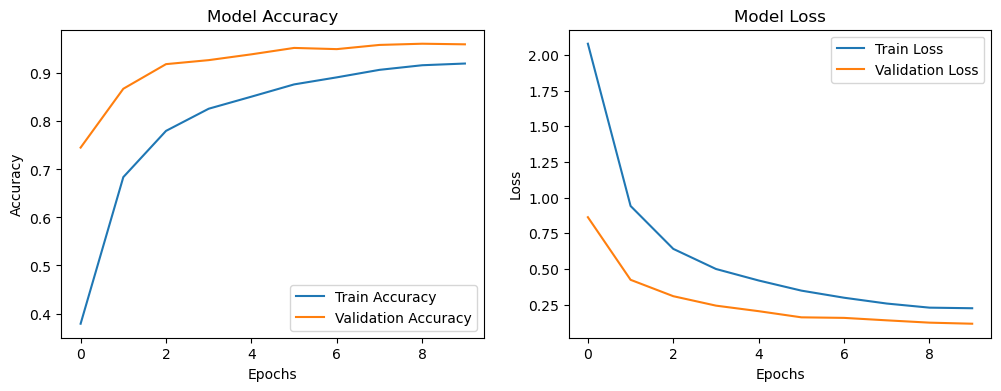

In [57]:
def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.show()

# Call the function
plot_training_history(history)

In [110]:
# Define variables to are going to be used for the create dataset method
dataset_path = 'ASL_Dataset/Train'
exclude_folders = ["J", "Z", "Nothing", "Space"]
num_images = 500  

# Use the method with the created variables
X, y, label_map = create_dataset(dataset_path, img_size=(32, 32), num_images=num_images, exclude_folders=exclude_folders)

# Verify the shapes of X and y
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the CNN model
input_shape = (32, 32, 1)  # Image shape with channel
num_classes = len(label_map)
model = build_cnn_model(input_shape, num_classes)

# Train the model
history = model.fit(
    X_train, 
    y_train, 
    epochs=15, 
    validation_data=(X_test, y_test), 
    batch_size=32
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.2f}")

Skipping folder: J
Skipping folder: Nothing
Skipping folder: Space
Skipping folder: Z
Shape of X: (12000, 32, 32, 1)
Shape of y: (12000,)
Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.0731 - loss: 3.1483 - val_accuracy: 0.2858 - val_loss: 2.3558
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.2673 - loss: 2.3375 - val_accuracy: 0.4429 - val_loss: 1.7753
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.3867 - loss: 1.8632 - val_accuracy: 0.5267 - val_loss: 1.5332
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4774 - loss: 1.5914 - val_accuracy: 0.5583 - val_loss: 1.3707
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5216 - loss: 1.4224 - val_accuracy: 0.5683 - val_loss: 1.3137
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5615 - loss: 1.2980 - val_accuracy: 0.6017 - val_loss: 1.2224
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5982 - loss: 1.1910 - val_ac

In the second training, I played around with the image size of 32 x 32 just to see what happens because the previous outcome was a bit too perfect in my opinion, and I wanted to know what happens when I shrink the image half in size.

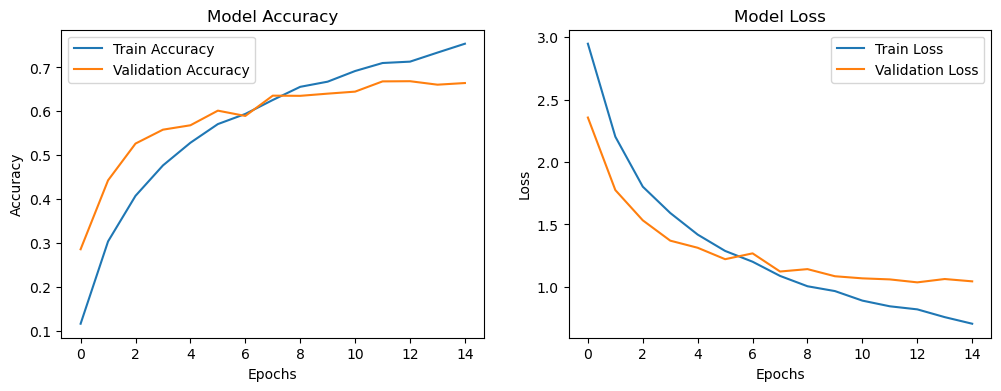

In [112]:
def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.show()

# Call the function
plot_training_history(history)

My model learns during training, as demonstrated by the model above; as a result, the loss decreases as the model's predictions get closer to the real data. The accuracy usually rises as the loss falls, suggesting that the model is predicting more accurately. which, if you look at the plot, is the case in my case. 

The model's accuracy, which is fairly low, is the only thing that I believe could be improved. So, let's see what happens if we maintain the same parameters, and increasing the image's size to 40 x 40 will allow us to observe the graph's reaction.

In [114]:
# Define variables to are going to be used for the create dataset method
dataset_path = 'ASL_Dataset/Train'
exclude_folders = ["J", "Z", "Nothing", "Space"]
num_images = 500  

# Use the method with the created variables
X, y, label_map = create_dataset(dataset_path, img_size=(40, 40), num_images=num_images, exclude_folders=exclude_folders)

# Verify the shapes of X and y
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the CNN model
input_shape = (40, 40, 1)  # Image shape with channel
num_classes = len(label_map)
model = build_cnn_model(input_shape, num_classes)

# Train the model
history = model.fit(
    X_train, 
    y_train, 
    epochs=15, 
    validation_data=(X_test, y_test), 
    batch_size=32
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.2f}")

Skipping folder: J
Skipping folder: Nothing
Skipping folder: Space
Skipping folder: Z
Shape of X: (12000, 40, 40, 1)
Shape of y: (12000,)
Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.1282 - loss: 2.9525 - val_accuracy: 0.5896 - val_loss: 1.4105
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.4794 - loss: 1.5869 - val_accuracy: 0.7050 - val_loss: 0.9704
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6038 - loss: 1.1922 - val_accuracy: 0.7625 - val_loss: 0.7704
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6689 - loss: 0.9663 - val_accuracy: 0.7733 - val_loss: 0.7253
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7047 - loss: 0.8661 - val_accuracy: 0.8050 - val_loss: 0.5912
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7417 - loss: 0.7260 - val_accuracy: 0.8379 - val_loss: 0.5263
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7701 - loss: 0.6428 -

In the final test I did with these parameters, I got the result I was hoping for. An accuracy that is not too high or too low. The reason why, in my opinion, this is a very pleasant result is because of the fact that the model that I created is not biased. This allows the model to still make mispredictions, which are a bit closer to real life since not every human is able to predict everything always right. But before we jump to conclusions, I would like to evaluate my model to see if it can actually perform the way I hope.

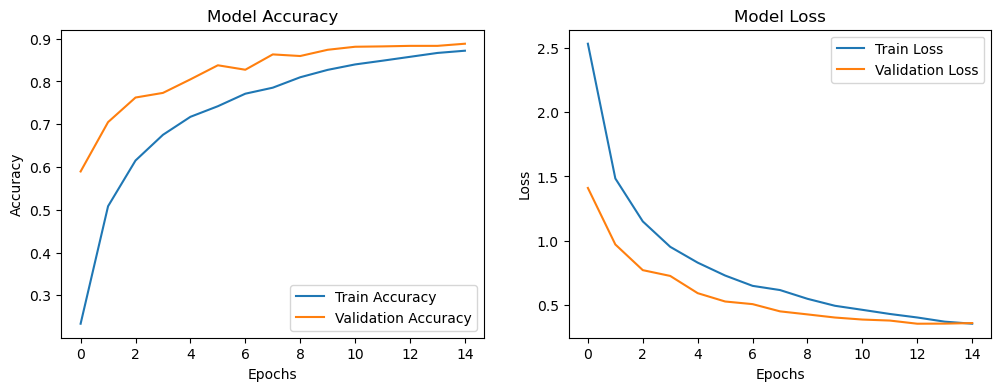

In [116]:
def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.show()

# Call the function
plot_training_history(history)

The evaluate_model_per_class method, is intended to evaluate a machine learning model's performance at the class level. This method calculates accuracy independently for every class, allowing for a deeper understanding of model behaviour and potential biases than traditional evaluation metrics that provide an aggregate accuracy.

I created this method in this case for a task that needs to be able to recognise gestures (sign language). It is also very helpful for problems where class imbalance or complexity is an issue. It facilitates the creation of reliable and equitable machine learning models by guaranteeing comprehensive and equitable evaluation. 

In [142]:
def evaluate_model_per_class(model, X_test, y_test, label_map, images_per_class=50):
    # Reverse the label map to get class names
    reverse_label_map = {idx: label for label, idx in label_map.items()}

    # Exclude specific classes from evaluation
    excluded_classes = {"J", "Z", "Nothing", "Space"}
    valid_classes = {label: idx for label, idx in label_map.items() if label not in excluded_classes}
    
    overall_accuracy = []

    for label, idx in valid_classes.items():
        # Get indices of test samples belonging to the current class
        class_indices = np.where(y_test == idx)[0]
        
        # Select a fixed number of images for evaluation
        num_images = min(images_per_class, len(class_indices))
        if num_images == 0:
            print(f"Skipping class '{label}' as it has no samples in the test set.")
            continue

        # Selecting random images for evaluation form the fixed number
        selected_indices = np.random.choice(class_indices, size=num_images, replace=False)
        selected_images = X_test[selected_indices]
        true_labels = y_test[selected_indices]
        
        # Predict class probabilities and compute accuracy
        predictions = model.predict(selected_images, verbose=0)
        predicted_labels = np.argmax(predictions, axis=1)
        class_accuracy = np.mean(predicted_labels == true_labels)
        overall_accuracy.append(class_accuracy)
        
        # Display class accuracy
        print(f"Class '{label}' - Accuracy: {class_accuracy * 100:.2f}%")
        
        # Visualize up to 10 images
        plt.figure(figsize=(10, 5))
        for i in range(min(10, num_images)):
            plt.subplot(2, 5, i + 1)
            plt.imshow(selected_images[i].reshape(40, 40), cmap='gray')
            true_label = reverse_label_map[true_labels[i]]
            predicted_label = reverse_label_map[predicted_labels[i]]
            color = 'green' if true_label == predicted_label else 'red'
            plt.title(f"True: {true_label}\nPred: {predicted_label}", color=color)
            plt.axis('off')
        plt.tight_layout()
        plt.show()

    # Compute and display overall accuracy
    mean_accuracy = np.mean(overall_accuracy)
    print(f"Overall accuracy across all valid classes: {mean_accuracy * 100:.2f}%")

A thorough assessment tool that offers in-depth information on a machine learning model's performance is the analyze_model_predictions method. Prediction visualisation, model confidence evaluation, and accuracy analysis across classes are its main objectives.

As shown further below, it can output for every class (letter) how high the prediction accuracy of that class is, which is a very nice way to evaluate the model.

Overall Prediction Analysis:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


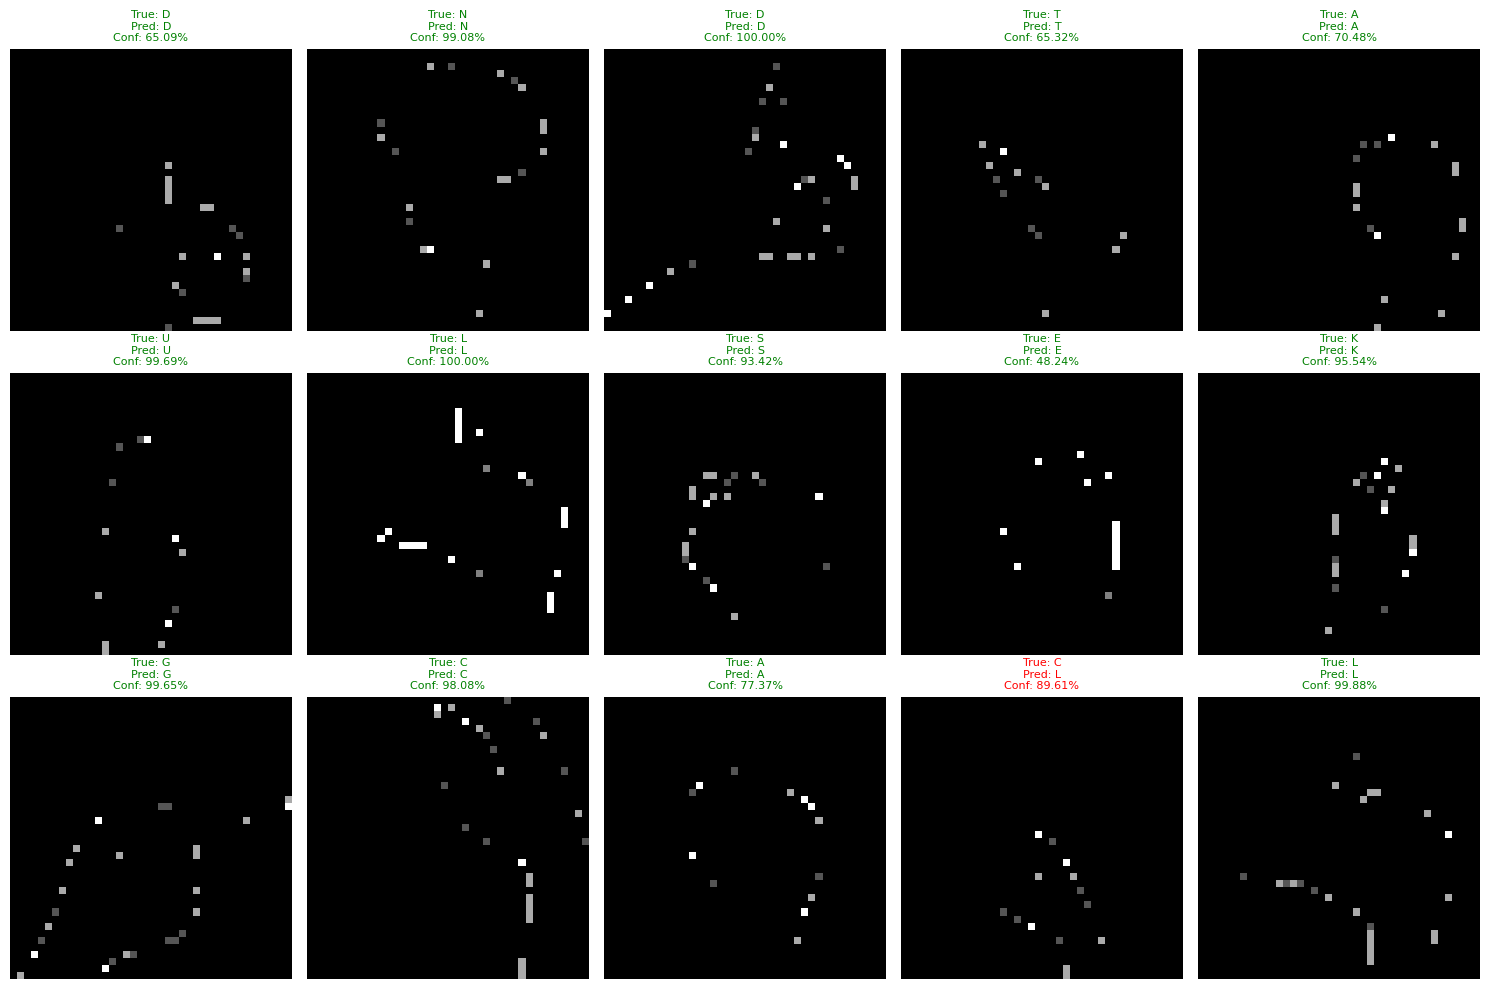

Per-Class Prediction Analysis:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━

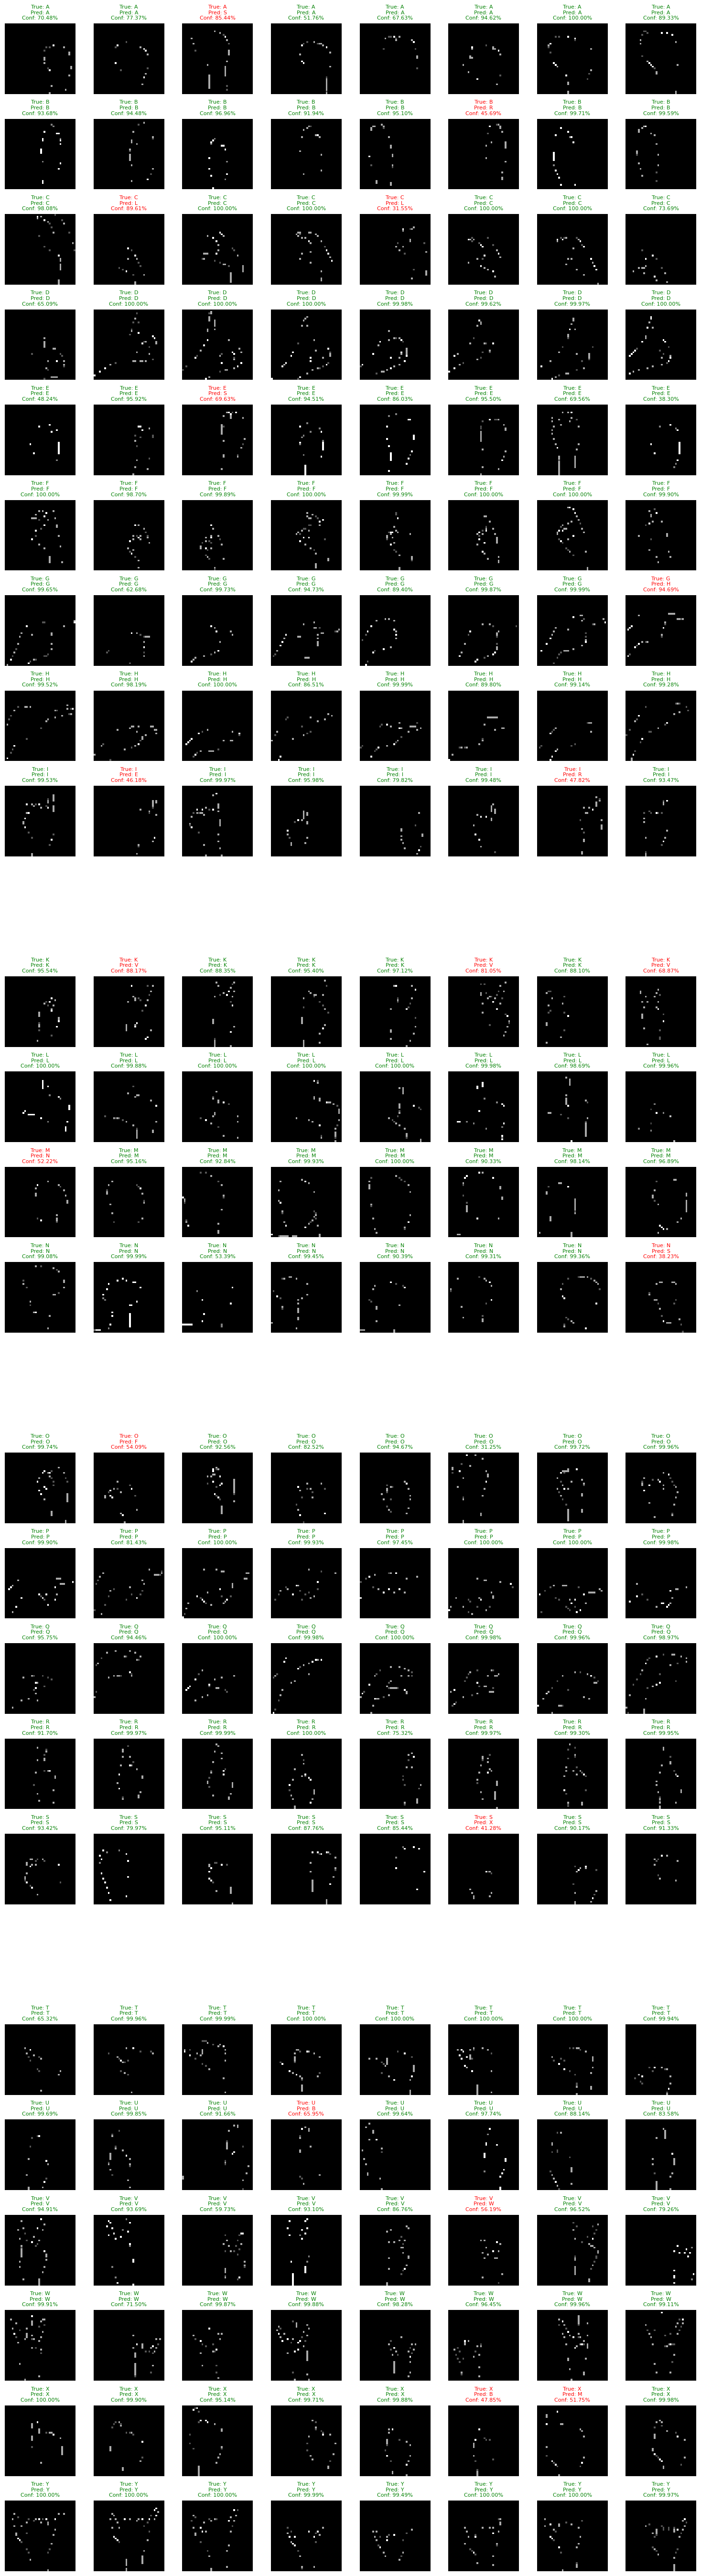

Class-Wise Accuracy Analysis:
Class 'A' - Accuracy: 100.00%


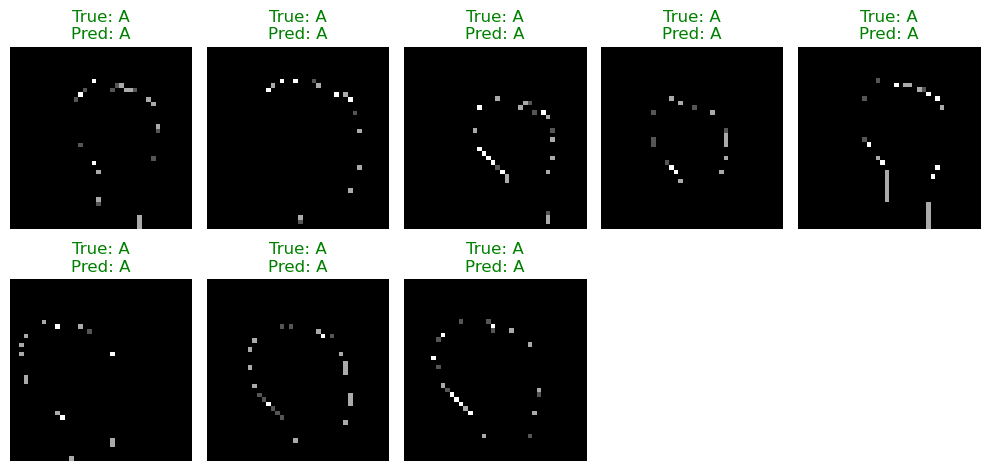

Class 'B' - Accuracy: 100.00%


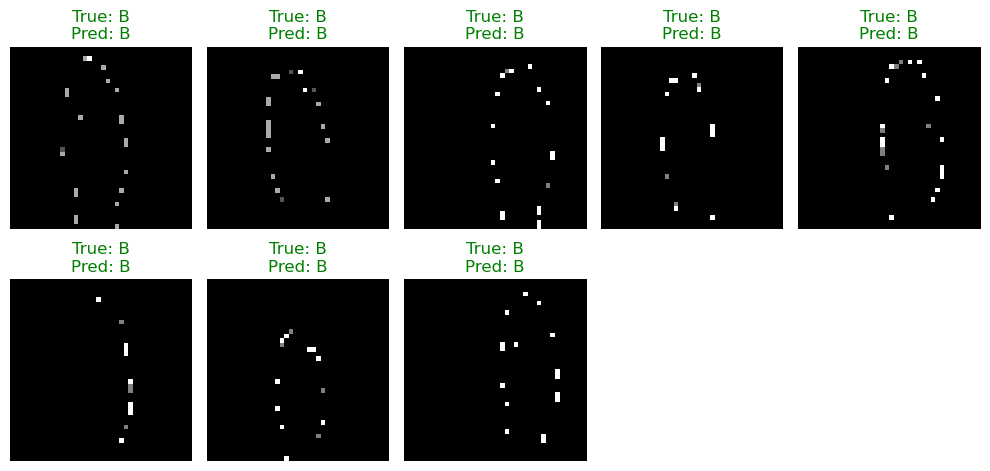

Class 'C' - Accuracy: 100.00%


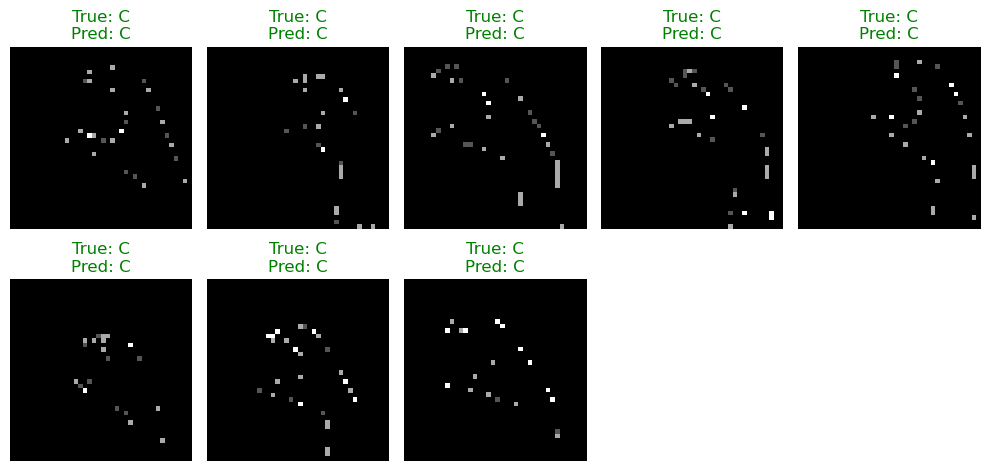

Class 'D' - Accuracy: 100.00%


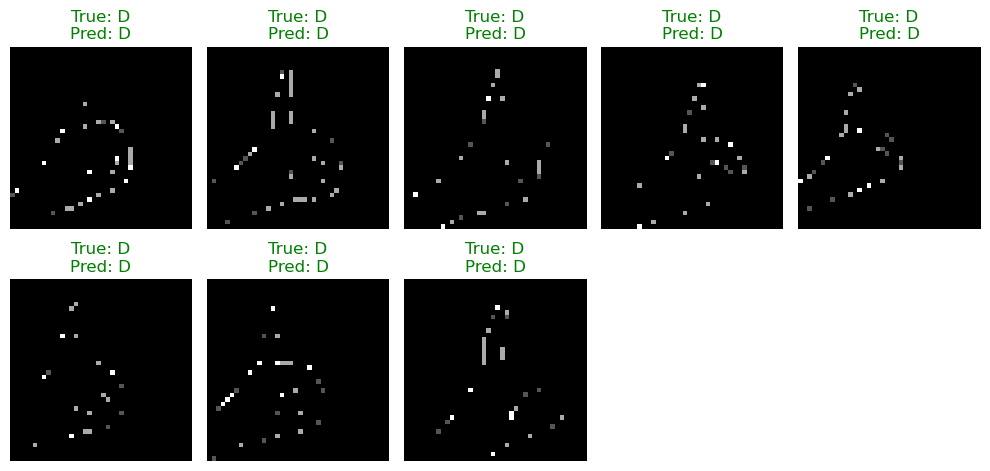

Class 'E' - Accuracy: 100.00%


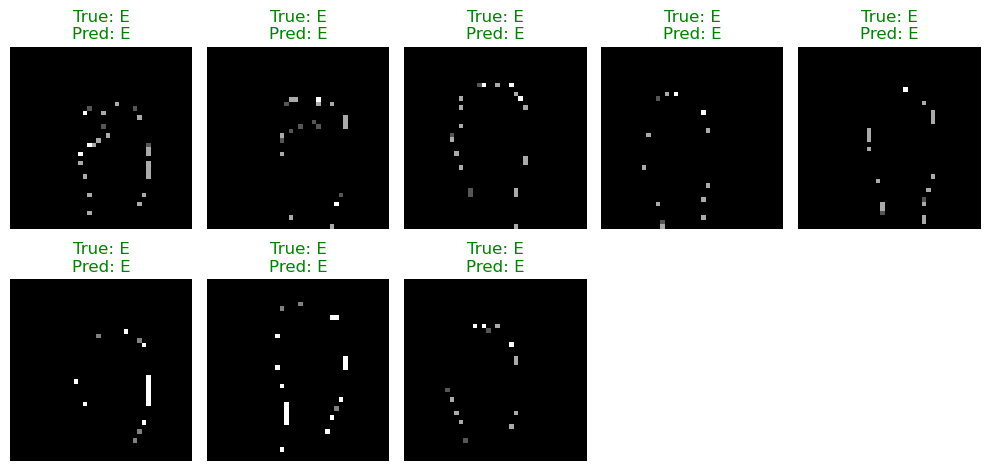

Class 'F' - Accuracy: 100.00%


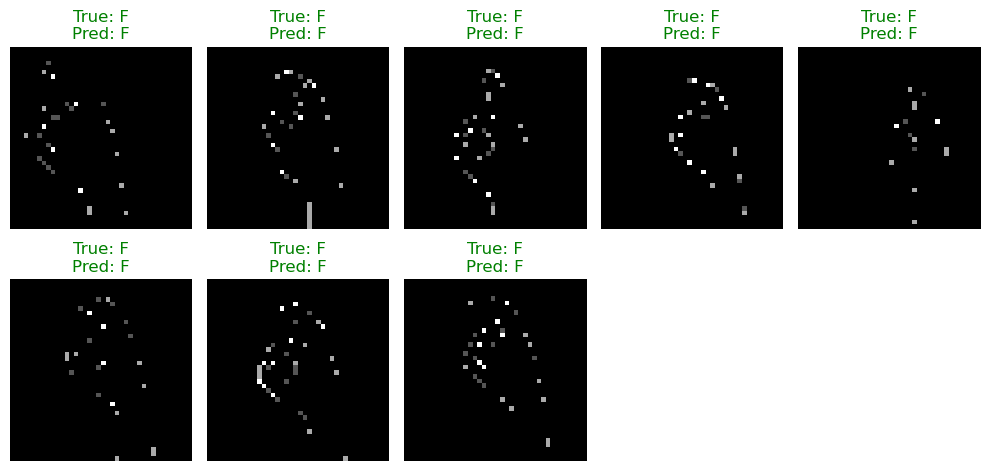

Class 'G' - Accuracy: 87.50%


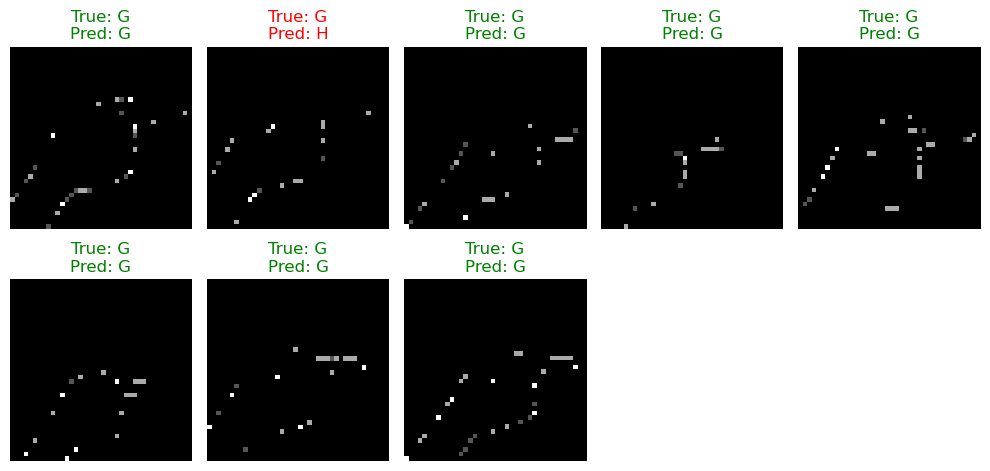

Class 'H' - Accuracy: 100.00%


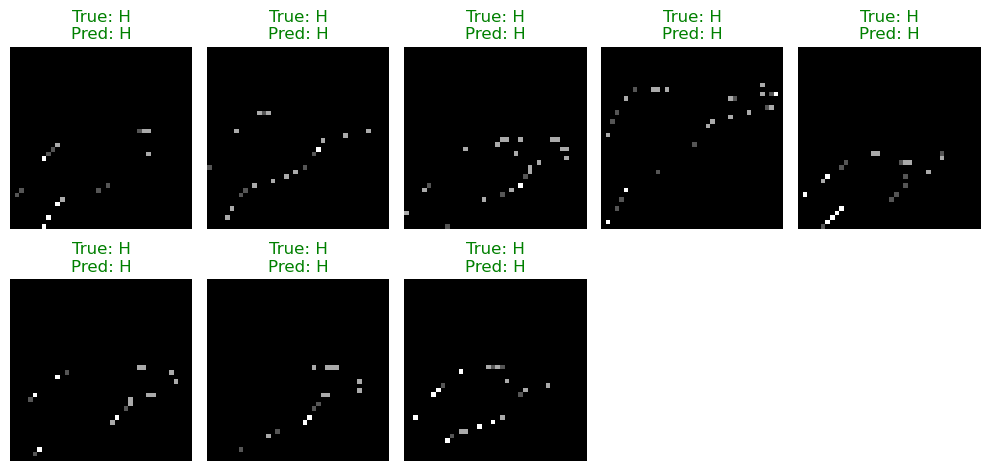

Class 'I' - Accuracy: 100.00%


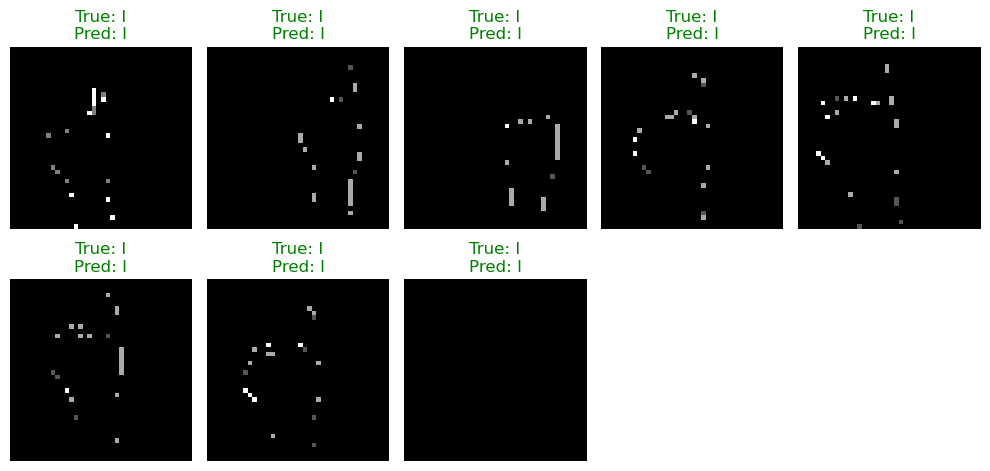

Class 'K' - Accuracy: 87.50%


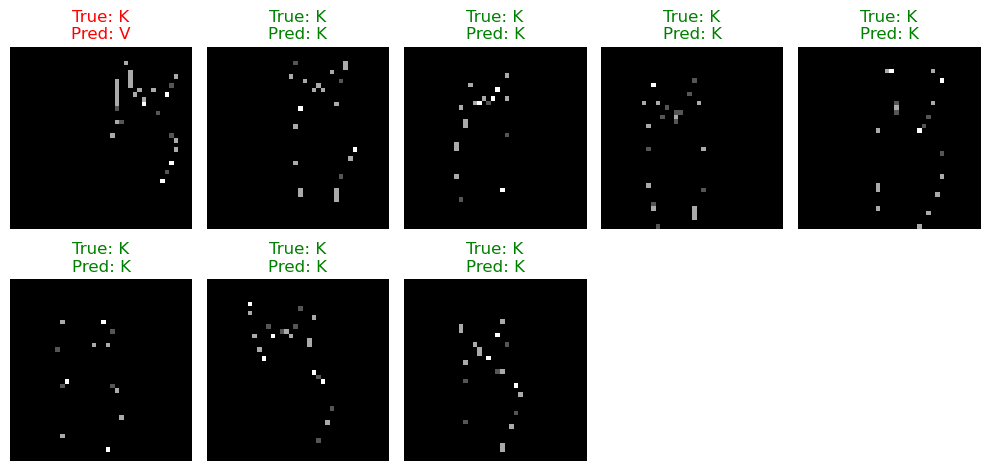

Class 'L' - Accuracy: 100.00%


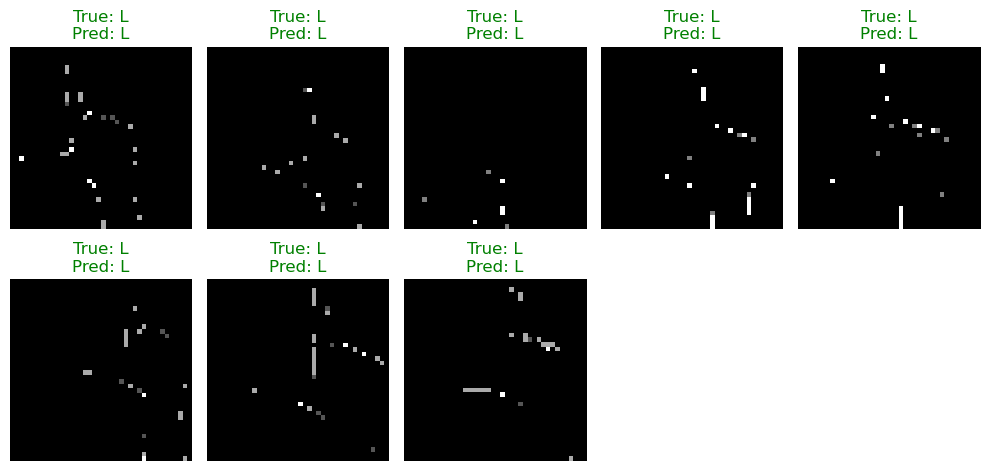

Class 'M' - Accuracy: 87.50%


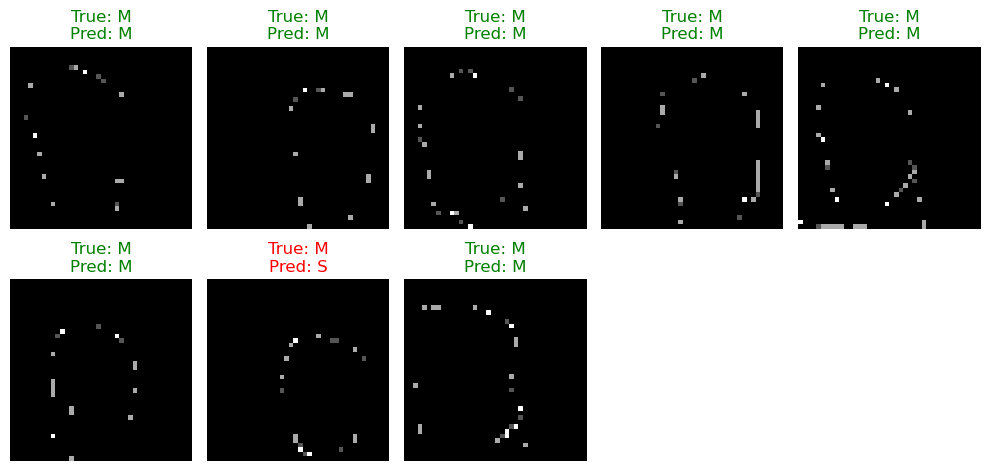

Class 'N' - Accuracy: 87.50%


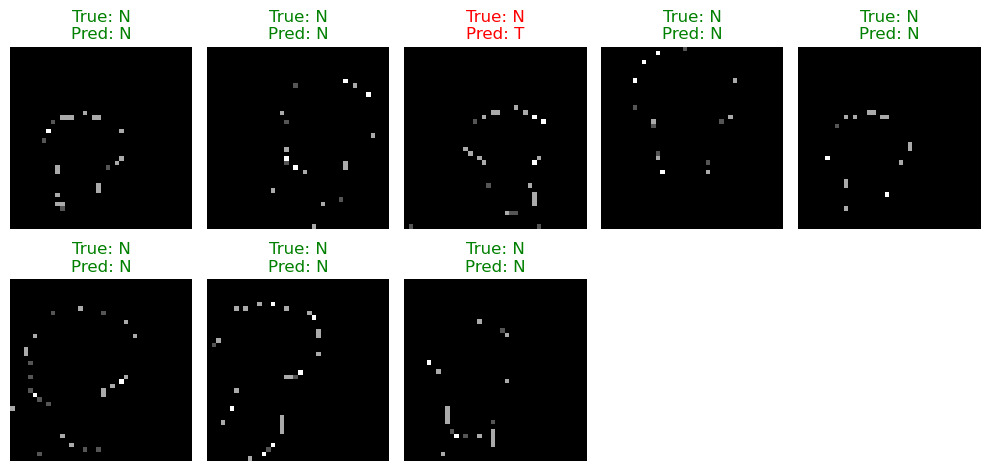

Class 'O' - Accuracy: 62.50%


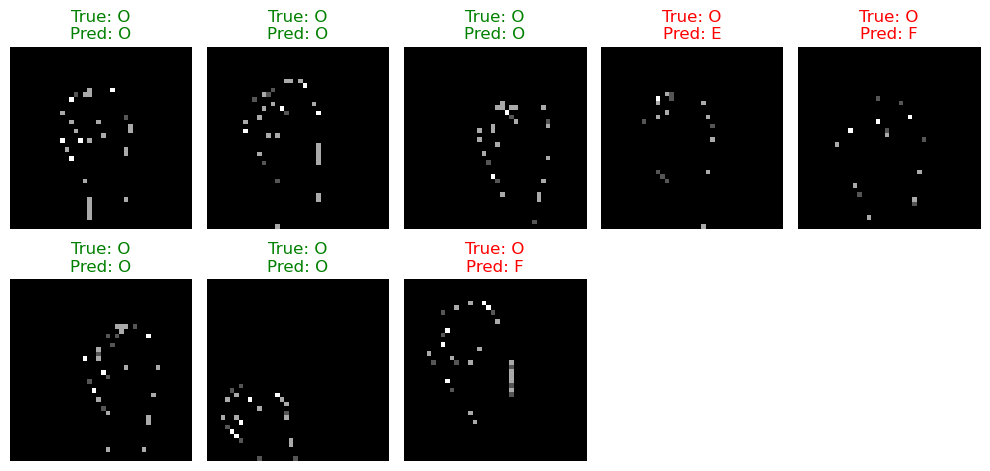

Class 'P' - Accuracy: 100.00%


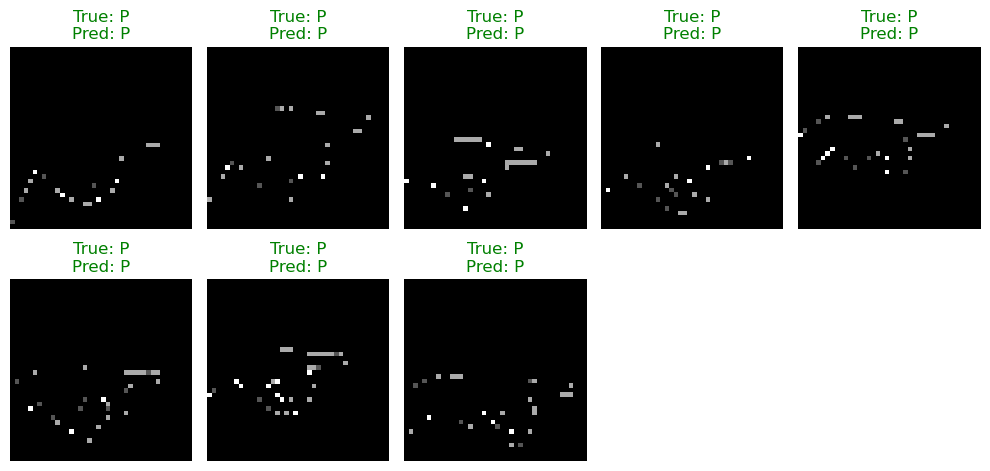

Class 'Q' - Accuracy: 100.00%


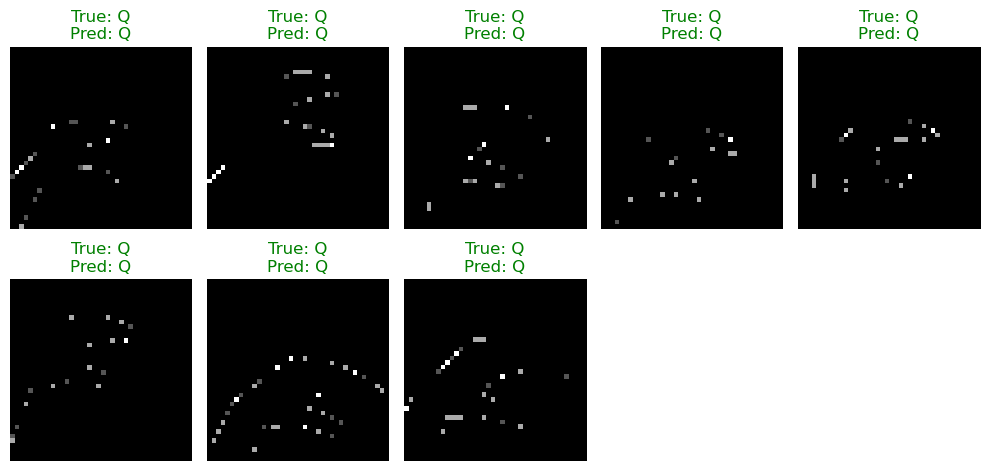

Class 'R' - Accuracy: 87.50%


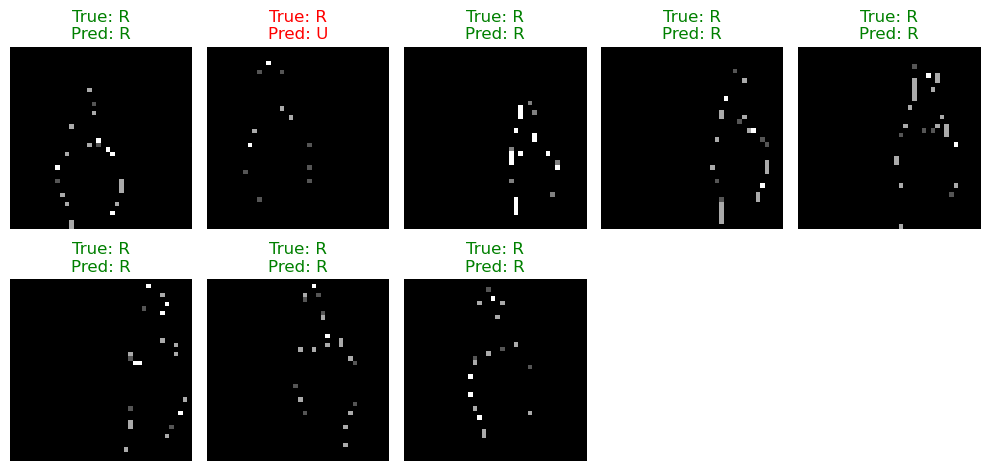

Class 'S' - Accuracy: 75.00%


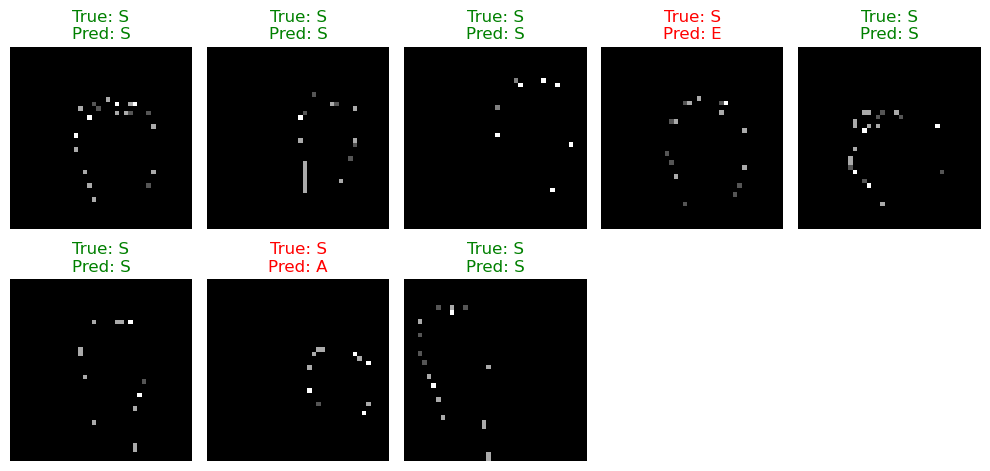

Class 'T' - Accuracy: 100.00%


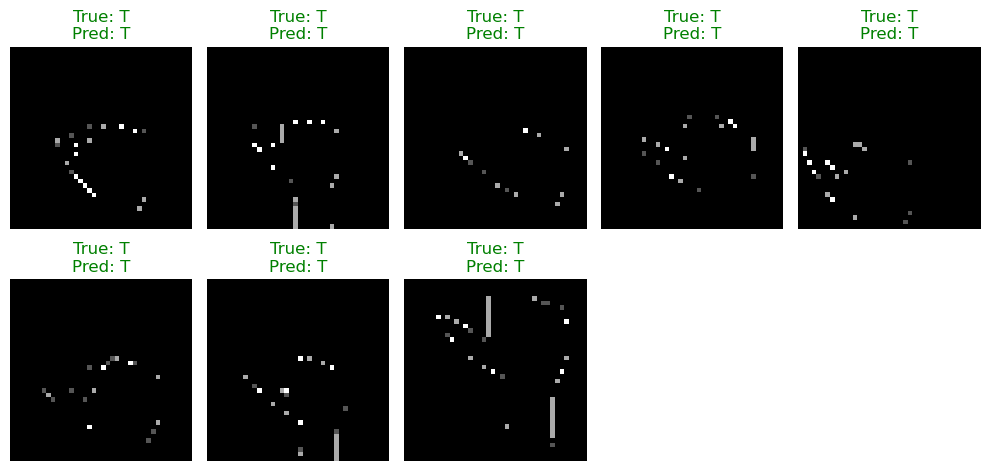

Class 'U' - Accuracy: 100.00%


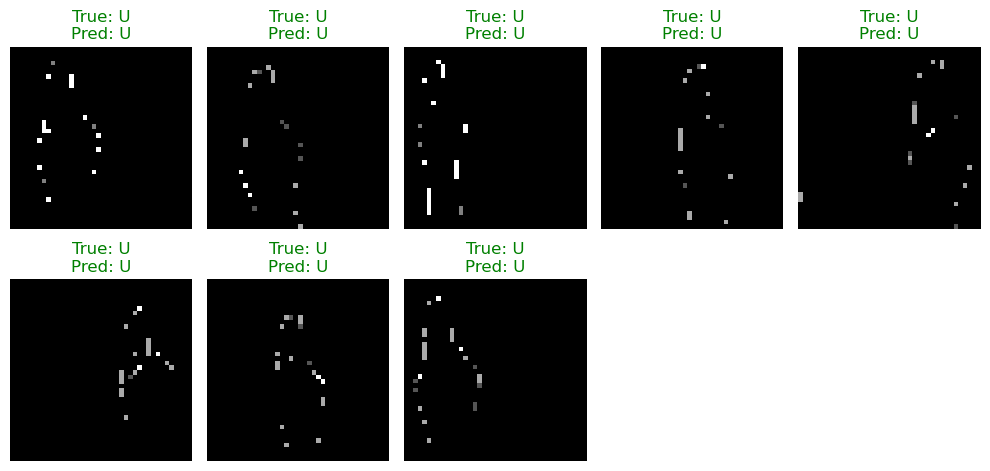

Class 'V' - Accuracy: 75.00%


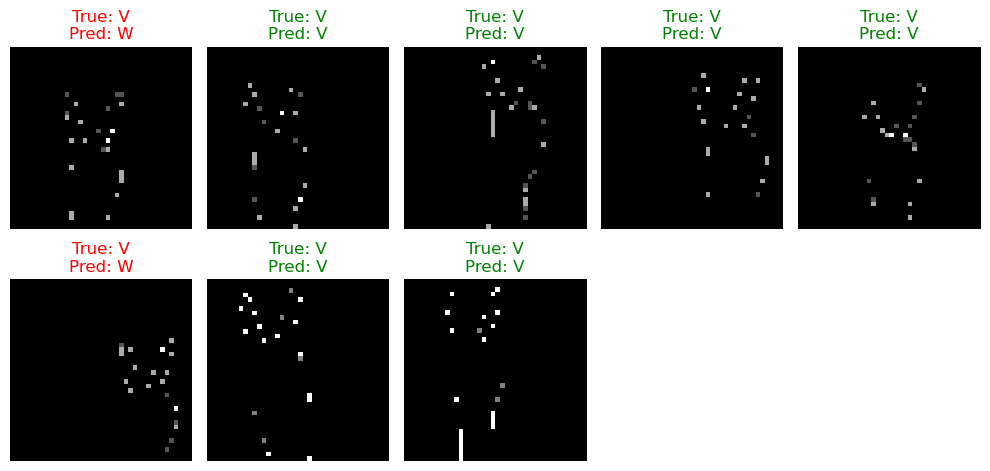

Class 'W' - Accuracy: 100.00%


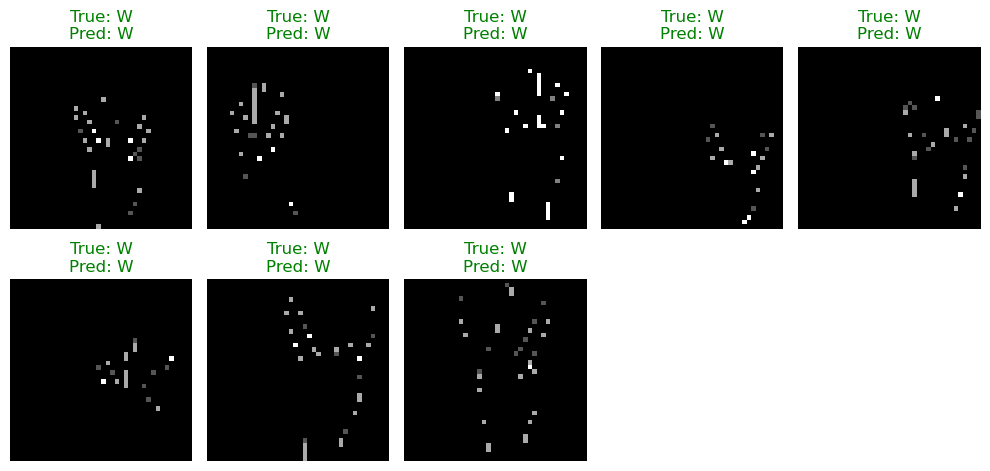

Class 'X' - Accuracy: 100.00%


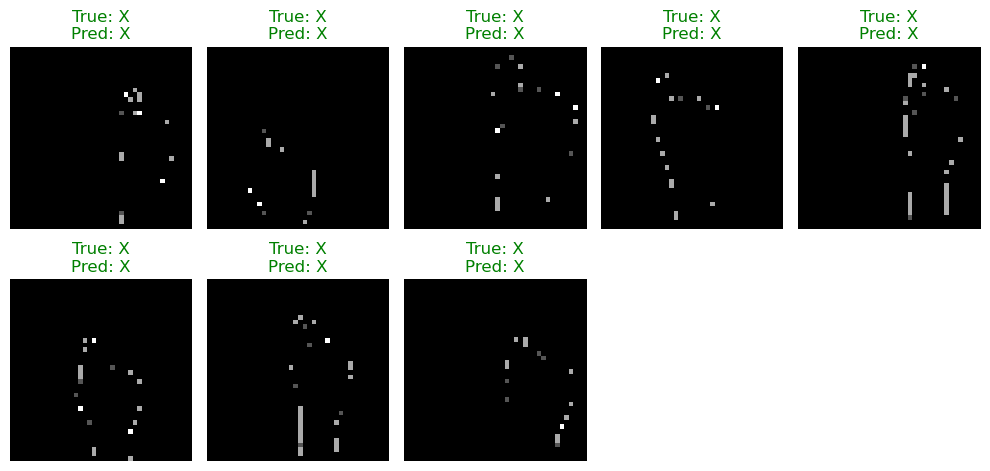

Class 'Y' - Accuracy: 100.00%


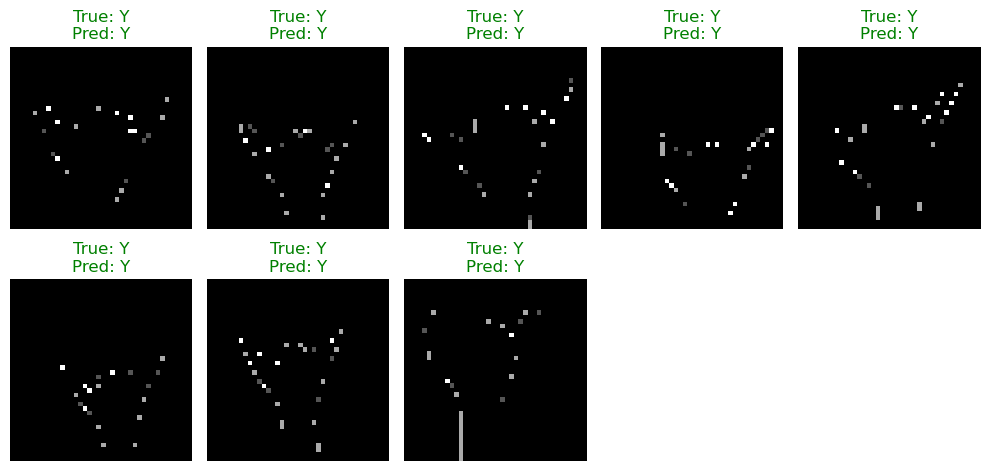

Overall accuracy across all valid classes: 93.75%


In [144]:
def analyze_model_predictions(model, X_test, y_test, label_map, img_size=(28, 28), num_predictions=15, num_per_class=8):
    
    # Convert labels if one-hot encoded
    if len(y_test.shape) > 1:
        y_test = np.argmax(y_test, axis=1)
    
    # Reverse label map for display
    reverse_label_map = {v: k for k, v in label_map.items()}
    
    # Overall predictions visualization
    print("Overall Prediction Analysis:")
    predictions = model.predict(X_test[:num_predictions])
    plt.figure(figsize=(15, 10))
    for i in range(num_predictions):
        plt.subplot(3, 5, i + 1)
        plt.imshow(X_test[i].reshape(img_size), cmap='gray')
        true_label = y_test[i]
        pred_label = np.argmax(predictions[i])
        is_correct = true_label == pred_label
        confidence = predictions[i][pred_label] * 100
        color = 'green' if is_correct else 'red'
        plt.title(f"True: {reverse_label_map[true_label]}\nPred: {reverse_label_map[pred_label]}\nConf: {confidence:.2f}%",
                  color=color, fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    # Per-class predictions visualization
    print("Per-Class Prediction Analysis:")
    class_samples = {cls: 0 for cls in range(len(label_map))}
    plt.figure(figsize=(15, len(label_map) * 2))
    for i, (img, true_label) in enumerate(zip(X_test, y_test)):
        if class_samples[true_label] < num_per_class:
            prediction = model.predict(img.reshape(1, *img_size, 1))
            pred_label = np.argmax(prediction)
            confidence = prediction[0][pred_label] * 100
            is_correct = true_label == pred_label
            color = 'green' if is_correct else 'red'
            
            plt.subplot(len(label_map), num_per_class, true_label * num_per_class + class_samples[true_label] + 1)
            plt.imshow(img.reshape(img_size), cmap='gray')
            plt.title(f"True: {reverse_label_map[true_label]}\nPred: {reverse_label_map[pred_label]}\nConf: {confidence:.2f}%",
                      color=color, fontsize=8)
            plt.axis('off')
            class_samples[true_label] += 1
        if all(count == num_per_class for count in class_samples.values()):
            break
    plt.tight_layout()
    plt.show()
    
    # Evaluate accuracy per class
    print("Class-Wise Accuracy Analysis:")
    evaluate_model_per_class(model, X_test, y_test, label_map, images_per_class=num_per_class)


analyze_model_predictions(model, 
                          X_test, 
                          y_test, 
                          label_map, 
                          img_size=(40, 40), 
                          num_predictions=15, 
                          num_per_class=8)

## Final Conclusion

In [ ]:
// Insert conclusion